## Machine Learning Notebook Week-2

### Table of Contents


##### 1. Classification Analysis 
##### 2. Logistic Regression 
##### 3. Classification Metrics  
##### 4. Data Imbalance (Stratified Analysis & SMOTE Analysis)
##### 5. KNN Regressor 
##### 6. KNN Classifier
##### 7. Gaussian Naive Bayes Algorithm
##### 8. Decision Tree Regressor 
##### 9. Decision Tree Classifier

##### Classification Analysis 

Classification Analysis is a machine learning technique used to predict a category or class label for given input data.
It helps in dividing data into predefined groups based on patterns learned from labeled examples during training.

In simple words:
Classification is used when we want to predict categories — like yes/no, spam/not spam, or types of animals — instead of numbers.

#### Logistic Regression

It determines the relationship between the input features (X) and a categorical dependent variable (y), where the goal is to classify observations into distinct groups or categories.
It is also known as, Logistic Regression (for binary classification).
The mathematical form of the Logistic (Sigmoid) Function is given as:

<p style='text-indent:25em'> <strong> P(y=1) = 1 / (1 + e<sup>-(β<sub>0</sub> + β<sub>1</sub>x)</sup>) </strong> </p>

where,

y = Dependent variable (categorical: e.g., 0 or 1) <br>
x = Independent variable <br>
β<sub>0</sub> = Intercept term <br>
β<sub>1</sub> = Coefficient of the independent variable <br>
e = Base of the natural logarithm <br>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [256]:
##### We will use loan default dataset

###### Data Dictionary 

| **Column Name**       | **Data Type**        | **Description**                                                                          | **Example Values** |
| --------------------- | -------------------- | ---------------------------------------------------------------------------------------- | ------------------ |
| **Loan_Default**      | Categorical (Yes/No) | Indicates whether the customer defaulted on the loan.                                    | Yes, No            |
| **Cbill_Score**       | Numeric (Integer)    | Customer’s credit score ranging between 300–900. Higher scores imply lower default risk. | 576, 785, 689      |
| **Gender**            | Categorical          | Gender of the applicant.                                                                 | Male, Female       |
| **Occupation**        | Categorical          | Primary source of employment or income.                                                  | Business, Job      |
| **Loan_Amount_Lakhs** | Numeric (Float)      | Loan amount sanctioned to the customer (in Lakhs).                                       | 7.03, 11.83, 18.10 |
| **Dependent**         | Categorical          | Indicates whether the applicant has financial dependents.                                | Yes, No            |
| **Age**               | Numeric (Integer)    | Age of the applicant in years.                                                           | 23, 47, 50         |
| **Income**            | Categorical          | Applicant’s income level based on financial profile.                                     | Low, Medium, High  |


In [3]:
df = pd.read_csv('loan_default.csv')

##### Model Pre-Processing

###### Before Model Building 2 important/Mandatory things to check

###### 1. No Missing values 

###### 2. No String/categorical data

###### Handling Missing Values

In [4]:
df.isnull().sum()

Loan_Default         0
Cbill_Score          0
Gender               0
Occupation           0
Loan_Amount_Lakhs    0
Dependent            0
Age                  0
Income               0
dtype: int64

###### Handling Categorical Data using Encoding techniques

In [5]:
df_num = df.select_dtypes(include= np.number)
df_cat = df.select_dtypes(exclude= np.number)

In [6]:
df_num.head()

,Cbill_Score,Loan_Amount_Lakhs,Age
0,576,18.10,23
1,663,11.03,27
2,689,11.83,49
3,785,7.03,50
4,661,9.29,47


In [7]:
df_cat.head()

,Loan_Default,Gender,Occupation,Dependent,Income
0,No,Male,Job,Yes,Low
1,No,Female,Job,Yes,Medium
2,Yes,Male,Business,No,Medium
3,No,Male,Job,No,High
4,Yes,Male,Job,No,Medium


In [8]:
encoded_cat_data = pd.get_dummies(df_cat.drop(columns='Loan_Default'),dtype=int,drop_first=True)

In [9]:
encoded_cat_data.head()

,Gender_Male,Occupation_Job,Dependent_Yes,Income_Low,Income_Medium
0,1,1,1,1,0
1,0,1,1,0,1
2,1,0,0,0,1
3,1,1,0,0,0
4,1,1,0,0,1


In [10]:
final_df = pd.concat([df_num,encoded_cat_data,df[['Loan_Default']]],axis=1)
final_df.head()

,Cbill_Score,Loan_Amount_Lakhs,Age,Gender_Male,Occupation_Job,Dependent_Yes,Income_Low,Income_Medium,Loan_Default
0,576,18.10,23,1,1,1,1,0,No
1,663,11.03,27,0,1,1,0,1,No
2,689,11.83,49,1,0,0,0,1,Yes
3,785,7.03,50,1,1,0,0,0,No
4,661,9.29,47,1,1,0,0,1,Yes


In [11]:
from sklearn.model_selection import train_test_split
X = final_df.drop(columns='Loan_Default')
y=final_df['Loan_Default']
xtrain,xtest,ytrain,ytest = train_test_split(X,y,train_size=0.7,test_size=0.3,random_state=100)

##### SKLEARN Logistic Regression

In [13]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(xtrain,ytrain)
y_pred = log_reg.predict(xtest)

##### Model Evaluation

In [14]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

###### Accuracy Score

In [15]:
accuracy_score(ytest,y_pred)

0.7966666666666666

###### Confusion matrix

In [16]:
confusion_matrix(ytest,y_pred)

array([[239,   0],
       [ 61,   0]])

###### Precision, Recall & F1 Score

In [18]:
print(classification_report(ytest,y_pred))

              precision    recall  f1-score   support

          No       0.80      1.00      0.89       239
         Yes       0.00      0.00      0.00        61

    accuracy                           0.80       300
   macro avg       0.40      0.50      0.44       300
weighted avg       0.63      0.80      0.71       300



c:\Users\shlok\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\shlok\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\shlok\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


###### ROC AUC Score

In [22]:
model_pred_prob = log_reg.predict_proba(xtest)[:,1]

In [23]:
roc_auc_score(ytest,model_pred_prob)

np.float64(0.6785101858838055)

###### ROC AUC Curve 

In [25]:
ytest_numbers = ytest.replace(to_replace=['No','Yes'],value=[0,1])

C:\Users\shlok\AppData\Local\Temp\ipykernel_3300\1084372574.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ytest_numbers = ytest.replace(to_replace=['No','Yes'],value=[0,1])


In [28]:
fpr,tpr,thres = roc_curve(ytest_numbers,model_pred_prob)

In [29]:
df = pd.DataFrame({'TPR': tpr, 'FPR': fpr, "THRESHOLD": thres})

In [30]:
pd.set_option('display.max_rows', 100)

Text(0, 0.5, 'TPR')

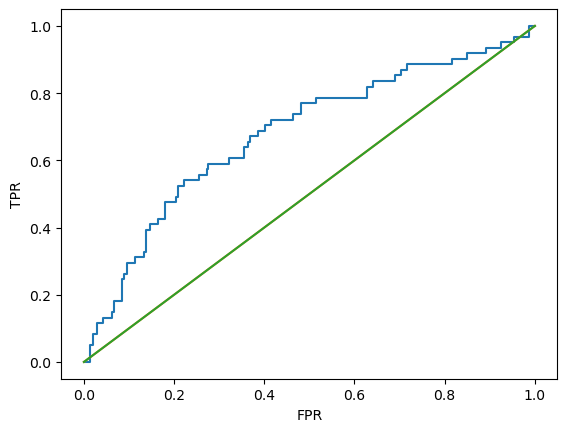

In [35]:
plt.plot(fpr,tpr)
plt.plot([[0,0],[1,1]])
plt.xlabel('FPR')
plt.ylabel("TPR")

##### Data Imabalance

##### SMOTE Analysis

In [ ]:
from imblearn

#### K- Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) is a simple, instance-based machine learning algorithm used for classification and regression.
It predicts the output for a new data point based on the majority class (for classification) or average value (for regression) of its k nearest data points in the training set.

In simple words:
KNN looks at the “k” closest examples in the dataset and decides the output based on what most of those neighbors say.

In [269]:
df = pd.read_csv('Salary.csv')
cat_data = df.select_dtypes(exclude = np.number)
num_data = df.select_dtypes(include = np.number)
encoded_cat_data = pd.get_dummies(cat_data,drop_first=True,dtype='int')
final_df = pd.concat([num_data,encoded_cat_data],axis=1)
x = final_df.drop(columns='Salary_Rupees')
y = final_df['Salary_Rupees']
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.7,test_size=0.3)

##### KNN Regressor

##### Model Evaluation

##### KNN Classifier

##### Model Evaluation

##### Hypertuned Model using Grid Search

##### KNN Tuned Model 

##### Gaussina Naive Bayes Algorithm

Gaussian Naïve Bayes is a probabilistic classification algorithm based on Bayes’ Theorem, which assumes that the features (independent variables) are independent of each other and follow a normal (Gaussian) distribution.
It calculates the probability of each class for a given data point and assigns the class with the highest probability as the prediction.

In simple words:
Gaussian Naïve Bayes predicts a category by using probability — it assumes each feature contributes independently and that data is normally distributed.

##### GNB Model

##### Model Evaluation

##### CART Models

CART stands for Classification and Regression Tree.
It is a decision tree-based algorithm used for both classification (predicting categories) and regression (predicting continuous values).
The model works by splitting the data into smaller subsets based on feature values, creating a tree-like structure of decisions that lead to a prediction.

##### Decision Tree

A Decision Tree is a model that makes decisions by following a flow of questions (conditions) about the input features.
Each internal node represents a feature test, each branch represents an outcome of that test, and each leaf node represents a final decision or prediction.
The algorithm selects the best feature to split the data using metrics like Gini Index or Information Gain.

In simple words:
A Decision Tree works like a flowchart — it splits the data step by step to make a final decision.

##### Decision Tree Regressor 

##### Model Evaluation

##### Decision Tree Classifier

##### Model Evaluation

##### Hyperparameter tuning
##### Decision tree Tuned Model

##### Model Evaluation